# Exploratory data analysis (EDA) of apartments data

**This Jupyter notebook does the following:**

- Imports the enriched apartment data, removes duplicated listings and outliers, and filters the apartments
- Performs univariate non-graphical EDA (summary statistics, quantiles, skewness, kurtosis, extreme values)
- Performs multivariate non-graphical EDA (cross-tabulation, pivot tables, correlation and covariance matrix)
- Performs univariate graphical EDA (line chart, boxplot, histogram, density plot, QQ-plot, bar chart, pie chart)
- Performs multivariate graphical EDA (scatterplots, scatterplot-matrix, hexbin plot, correlation heatmap, bubble plot)

## Libraries and settings

In [43]:
# Libraries
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import pylab as py

# seaborn graphics settings
sns.set(color_codes=True)

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Show current working directory
print(os.getcwd())

/workspaces/ARM-Stejsnat/Week_10


## Univariate non-graphical exploratory data analysis (EDA)

### Importing the enriched apartment data
Note: These are the enriched data from week 09 including outliers (see section 'Remove outliers' below).

In [44]:
# Read and select variables
df_orig = pd.read_csv("./Data/apartments_data_enriched.csv")[['web-scraper-order',
                                                                'address_raw',
                                                                'lat',
                                                                'lon',
                                                                'bfs_number',
                                                                'bfs_name',
                                                                'rooms', 
                                                                'area', 
                                                                'luxurious', 
                                                                'price', 
                                                                'price_per_m2',
                                                                'pop',
                                                                'pop_dens',
                                                                'emp',
                                                                'frg_pct',
                                                                'mean_taxable_income']]

# Remove duplicated listings (same address, rooms, area and price; the
# 'web-scraper-order' differs for every scraped row and is therefore not used)
df_orig = df_orig.drop_duplicates(subset=['address_raw', 'rooms', 'area', 'price'])
df_orig.head(5)

# Remove missing values
df_orig = df_orig.dropna()
df_orig.head(5)

,web-scraper-order,address_raw,lat,lon,bfs_number,bfs_name,rooms,area,luxurious,price,price_per_m2,pop,pop_dens,emp,frg_pct,mean_taxable_income
0,1693998201-1,"Neuhusstrasse 6, 8630 Rüti ZH, ZH",47.252171,8.845797,118,Rüti (ZH),3.0,49.0,0,1441.0,29.41,12286,1221.272366,5053.0,24.841283,65362.042683
1,1693998233-172,"Widacherstrasse 5, 8630 Rüti ZH, ZH",47.252087,8.854919,118,Rüti (ZH),3.0,111.0,0,2600.0,23.42,12286,1221.272366,5053.0,24.841283,65362.042683
2,1693998256-331,"Widenweg 14, 8630 Rüti ZH, ZH",47.253670,8.853993,118,Rüti (ZH),3.0,58.0,0,1490.0,25.69,12286,1221.272366,5053.0,24.841283,65362.042683
3,1693998265-381,"Rain 1, 8630 Rüti ZH, ZH",47.259834,8.851705,118,Rüti (ZH),4.0,118.0,0,3240.0,27.46,12286,1221.272366,5053.0,24.841283,65362.042683
4,1693998276-419,"Bachtelstrasse 24b, 8630 Rüti ZH, ZH",47.266113,8.866872,118,Rüti (ZH),3.0,66.0,0,1450.0,21.97,12286,1221.272366,5053.0,24.841283,65362.042683


### Remove outliers
Replace the example conditions below with the thresholds used in this exercise. Apartments with an area above 500 m² or a rental price below CHF 10 per m² are excluded from the working subset. These cutoffs are intentionally conservative: the 99th percentile of area is about 234 m², while the 1st percentile of price per m² is about CHF 13.5. Such listings are flagged for this analysis, but unusual apartments are not automatically errors and may need individual review. The original CSV file is not changed. On the current dataset, this removes 6 listings (781 rows before and 775 after filtering).

In [45]:
# Number of rows before removing outliers
rows_before = df_orig.shape[0]
print("Number of rows before removing outliers:", rows_before)

# Exclude only the most extreme area and price-per-square-metre values
df_orig = df_orig.loc[(df_orig["area"] <= 500) &
                      (df_orig["price_per_m2"] >= 10)].copy()

# Number of rows after removing outliers
print("Number of rows after removing outliers:", df_orig.shape[0])

Number of rows before removing outliers: 781
Number of rows after removing outliers: 775


### Quantiles original values

In [46]:
df_orig[['price','rooms', 'area', 'price_per_m2', 'pop_dens']].quantile(q=[0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]).round(2)

,price,rooms,area,price_per_m2,pop_dens
0.05,1347.0,1.0,26.0,18.66,340.80
0.10,1499.4,1.5,42.4,20.36,525.66
0.25,1847.5,2.5,63.0,23.39,1044.63
0.50,2392.0,3.5,86.0,27.95,1662.60
0.75,3050.0,4.5,108.0,38.08,4778.99
0.90,3950.0,4.5,140.0,52.18,4778.99
0.95,4969.0,5.5,160.0,66.57,4778.99


### Filter apartments

In [47]:
# Filter apartments (replace '<= 5000' by the respective operator and quantile)
df = df_orig.loc[df_orig['pop_dens'] <= 5000]

### Shape (number of rows and colums)

In [48]:
# Number of rows and columns
print(df.shape)

(775, 16)


### Data types

In [49]:
df.dtypes

web-scraper-order          str
address_raw                str
lat                    float64
lon                    float64
bfs_number               int64
bfs_name                   str
rooms                  float64
area                   float64
luxurious                int64
price                  float64
price_per_m2           float64
pop                      int64
pop_dens               float64
emp                    float64
frg_pct                float64
mean_taxable_income    float64
dtype: object

### Summary statistics of numeric variables

In [50]:
df.describe()

,lat,lon,bfs_number,rooms,area,luxurious,price,price_per_m2,pop,pop_dens,emp,frg_pct,mean_taxable_income
count,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000,775.00000,775.000000,775.000000,775.000000,775.000000,775.000000,775.000000
mean,47.407569,8.600268,186.485161,3.409677,88.609032,0.011613,2656.16000,33.403703,160137.187097,2496.216782,176029.569032,27.814822,80485.263464
std,0.085413,0.117556,81.578164,1.287074,39.630668,0.107205,1282.27907,16.821985,186145.797173,1743.858319,223181.119622,7.559289,14377.298811
min,47.195290,8.367652,1.000000,1.000000,8.000000,0.000000,86.00000,10.750000,698.000000,87.959866,129.000000,7.547170,62000.541872
25%,47.360918,8.518415,121.000000,2.500000,63.000000,0.000000,1847.50000,23.390000,8775.000000,1044.628957,3460.000000,24.535004,71011.946771
50%,47.395222,8.562193,230.000000,3.500000,86.000000,0.000000,2392.00000,27.950000,27746.000000,1662.597326,19226.000000,28.043732,80595.528256
75%,47.481298,8.710436,261.000000,4.500000,108.000000,0.000000,3050.00000,38.080000,420217.000000,4778.994655,491193.000000,32.458468,82932.737704
max,47.693893,8.915933,298.000000,8.500000,282.000000,1.000000,9950.00000,149.900000,420217.000000,4778.994655,491193.000000,46.226483,174434.537050


### Statistical measures (min, max, std, mean, median, count) for selected variables

In [51]:
# Price
print('Price:',
      'Count:', round(df.price.count(), 1),
      'Min:', round(df.price.min(), 1),
      'Max:', round(df.price.max(), 1),
      'Mean:', round(df.price.mean(), 1),
      'Median:', round(df.price.median(), 1),
      'Std:', round(df.price.std(), 1))

# Area
print('Area:',
      'Count:', round(df.area.count(), 1),
      'Min:', round(df.area.min(), 1),
      'Max:', round(df.area.max(), 1),
      'Mean:', round(df.area.mean(), 1),
      'Median:', round(df.area.median(), 1),
      'Std:', round(df.area.std(), 1))

Price: Count: 775 Min: 86.0 Max: 9950.0 Mean: 2656.2 Median: 2392.0 Std: 1282.3
Area: Count: 775 Min: 8.0 Max: 282.0 Mean: 88.6 Median: 86.0 Std: 39.6


### Skewness

In [52]:
df[['price','rooms', 'area']].skew()

price    2.167941
rooms    0.192588
area     0.877163
dtype: float64

### Kurtosis

In [53]:
df[['price','rooms', 'area']].kurtosis()

price    6.887283
rooms    0.131407
area     1.952477
dtype: float64

### Extreme values

In [54]:
# Low costs apartments
df[df['price_per_m2'] <= 10]

,web-scraper-order,address_raw,lat,lon,bfs_number,bfs_name,rooms,area,luxurious,price,price_per_m2,pop,pop_dens,emp,frg_pct,mean_taxable_income


In [55]:
# Very expansive apartments
df[df['price_per_m2'] >= 100]

,web-scraper-order,address_raw,lat,lon,bfs_number,bfs_name,rooms,area,luxurious,price,price_per_m2,pop,pop_dens,emp,frg_pct,mean_taxable_income
11,1693998201-16,"Wolframplatz 1, 8045 Zürich, ZH",47.362282,8.522193,261,Zürich,2.0,32.0,0,3515.0,109.84,420217,4778.994655,491193.0,32.458468,82932.737704
20,1693998214-82,"Baurstrasse 29, 8008 Zürich, ZH",47.355923,8.554498,261,Zürich,1.5,30.0,0,3790.0,126.33,420217,4778.994655,491193.0,32.458468,82932.737704
21,1693998214-83,"Baurstrasse 29, 8008 Zürich, ZH",47.355923,8.554498,261,Zürich,1.5,25.0,0,3490.0,139.60,420217,4778.994655,491193.0,32.458468,82932.737704
107,1693998280-434,"Neugasse 40, 8005 Zürich, ZH",47.382469,8.530180,261,Zürich,1.0,11.0,0,1120.0,101.82,420217,4778.994655,491193.0,32.458468,82932.737704
154,1693998305-585,"Steinstrasse 35, 8003 Zürich, ZH",47.366997,8.520324,261,Zürich,1.0,15.0,0,1500.0,100.00,420217,4778.994655,491193.0,32.458468,82932.737704
171,1693998309-621,"Baurstrasse 29, 8008 Zürich, ZH",47.355923,8.554498,261,Zürich,1.5,30.0,0,3890.0,129.67,420217,4778.994655,491193.0,32.458468,82932.737704
185,1693998317-658,"8004 Zürich, ZH",47.380417,8.525352,261,Zürich,1.0,10.0,0,1499.0,149.90,420217,4778.994655,491193.0,32.458468,82932.737704


### Get a list of categories of categorical variable

In [56]:
np.array(pd.Categorical(df['bfs_name']).categories)

array(['Adliswil', 'Aeugst am Albis', 'Affoltern am Albis', 'Altikon',
       'Andelfingen', 'Bachenbülach', 'Bassersdorf', 'Bauma',
       'Bonstetten', 'Brütten', 'Bülach', 'Dielsdorf', 'Dietikon',
       'Dietlikon', 'Dättlikon', 'Dübendorf', 'Dürnten', 'Egg', 'Eglisau',
       'Elsau', 'Embrach', 'Fehraltorf', 'Feuerthalen',
       'Freienstein-Teufen', 'Fällanden', 'Glattfelden', 'Gossau (ZH)',
       'Greifensee', 'Hausen am Albis', 'Hedingen', 'Herrliberg',
       'Hettlingen', 'Hinwil', 'Hittnau', 'Hochfelden', 'Hombrechtikon',
       'Höri', 'Hüttikon', 'Kloten', 'Knonau', 'Küsnacht (ZH)',
       'Langnau am Albis', 'Laufen-Uhwiesen', 'Lindau', 'Lufingen',
       'Maur', 'Meilen', 'Mettmenstetten', 'Männedorf', 'Mönchaltorf',
       'Neerach', 'Neftenbach', 'Niederglatt', 'Niederhasli',
       'Niederweningen', 'Nürensdorf', 'Oberengstringen', 'Oberglatt',
       'Obfelden', 'Oetwil am See', 'Oetwil an der Limmat', 'Opfikon',
       'Ossingen', 'Pfungen', 'Pfäffikon', 'Regensd

## Multivariate non-graphical exploratory data analysis (EDA)

### Cross-tabulation

In [57]:
pd.crosstab(df['luxurious'], df['rooms'])

rooms,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5,5.0,5.5,6.0,6.5,7.0,7.5,8.5
luxurious,,,,,,,,,,,,,,,
0,52,33,39,134,44,200,28,162,3,52,2,11,2,3,1
1,0,0,0,6,0,3,0,0,0,0,0,0,0,0,0


### Pivot tables

In [58]:
# Using pivot_table to reshape the data and calculate means 
pd.pivot_table(df[['rooms', 'price', 'price_per_m2', 'area', 'luxurious']],
               index=['rooms', 'luxurious'],
               values=['price', 'price_per_m2', 'area'],
               aggfunc=(np.mean, 'count'))

area             price              price_per_m2           
                count        mean count         mean        count       mean
rooms luxurious                                                             
1.0   0            52   32.057692    52  1306.346154           52  50.168077
1.5   0            33   36.424242    33  2140.787879           33  64.503636
2.0   0            39   54.589744    39  2155.846154           39  42.528462
2.5   0           134   66.880597   134  2382.253731          134  36.959701
      1             6   72.166667     6  3339.500000            6  45.978333
3.0   0            44   68.159091    44  1964.022727           44  28.677955
3.5   0           200   89.770000   200  2648.980000          200  29.494700
      1             3  101.666667     3  6036.666667            3  59.826667
4.0   0            28   98.464286    28  2852.357143           28  29.646429
4.5   0           162  114.722222   162  3078.462963          162  26.473457
5.0   0             3  108.000000     3  2881.666667            3  26.376667
5.5   0            52  153.250000    52  3590.653846           52  23.587500
6.0   0             2  185.000000     2  3800.000000            2  22.365000
6.5   0            11  167.363636    11  4114.272727           11  24.638182
7.0   0             2  175.000000     2  6350.000000            2  36.325000
7.5   0             3  205.000000     3  4765.000000            3  23.273333
8.5   0             1  210.000000     1  8500.000000            1  40.480000

### Correlation matrix

In [59]:
corr = df[['rooms', 
          'area', 
          'price', 
          'price_per_m2',
          'pop_dens',
          'frg_pct']].corr()
corr

,rooms,area,price,price_per_m2,pop_dens,frg_pct
rooms,1.000000,0.838747,0.462009,-0.468538,-0.318676,-0.272464
area,0.838747,1.000000,0.601206,-0.456137,-0.267418,-0.259601
price,0.462009,0.601206,1.000000,0.269032,0.293945,0.095010
price_per_m2,-0.468538,-0.456137,0.269032,1.000000,0.588873,0.330646
pop_dens,-0.318676,-0.267418,0.293945,0.588873,1.000000,0.655295
frg_pct,-0.272464,-0.259601,0.095010,0.330646,0.655295,1.000000


### Covariance matrix

In [60]:
cov = df[['rooms', 
          'area', 
          'price', 
          'price_per_m2',
          'pop_dens',
          'frg_pct']].cov()
cov

,rooms,area,price,price_per_m2,pop_dens,frg_pct
rooms,1.656560,42.782471,7.624938e+02,-10.144374,-7.152613e+02,-2.650905
area,42.782471,1570.589841,3.055183e+04,-304.091186,-1.848134e+04,-77.771276
price,762.493798,30551.830078,1.644240e+06,5803.155414,6.572936e+05,920.940580
price_per_m2,-10.144374,-304.091186,5.803155e+03,282.979182,1.727469e+04,42.045727
pop_dens,-715.261286,-18481.340290,6.572936e+05,17274.693783,3.041042e+06,8638.316217
frg_pct,-2.650905,-77.771276,9.209406e+02,42.045727,8.638316e+03,57.142856


## Univariate graphical exploratory data analysis (EDA)

### Line chart (matplotlib)

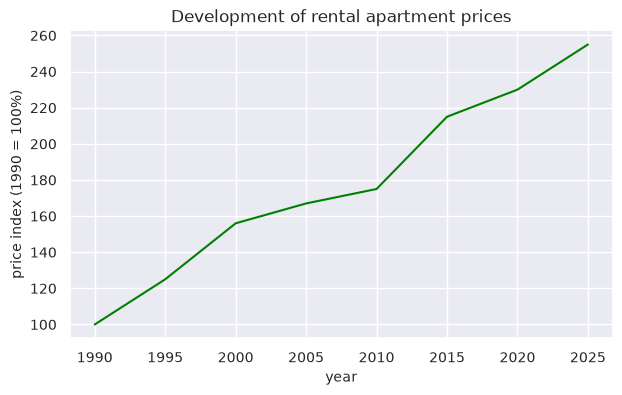

In [61]:
# Generate some useful values (time series)
x = [1990, 1995, 2000, 2005, 2010, 2015, 2020, 2025]
y = [100, 125, 156, 167, 175, 215, 230, 255]

# Create figure
fig = plt.figure(figsize=(7,4))
plt.plot(x, y, color="green")
plt.title('Development of rental apartment prices', fontsize=12)
plt.xlabel('year', fontsize=10)
plt.ylabel('price index (1990 = 100%)', fontsize=10)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.show()

### Boxplot (seaborn)

<Axes: xlabel='area'>

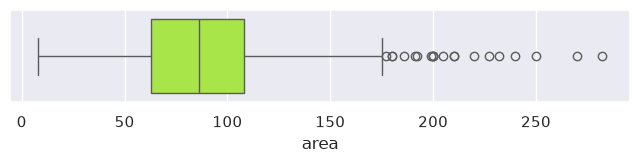

In [62]:
plt.figure(figsize=(8,1.2))
plt.ticklabel_format(style='plain')
sns.boxplot(x=df['area'], color="greenyellow")

### Histogram  (matplotlib)

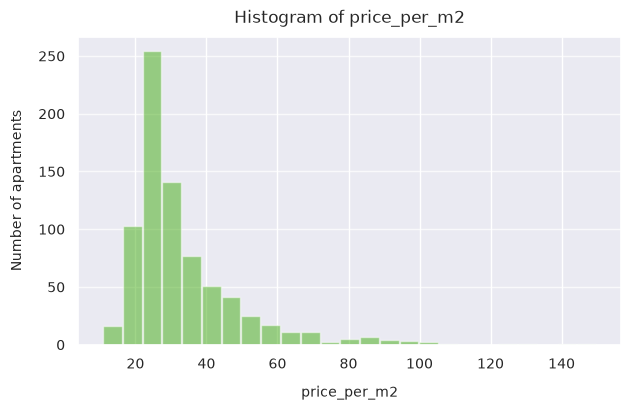

In [63]:
import matplotlib.pyplot as plt
import numpy as np

# Plot Histogram
fig = plt.figure( figsize=(7,4))

plt.xticks(fontsize=14, rotation=0)
plt.yticks(fontsize=14, rotation=0)

n, bins, patches = plt.hist(x=df['price_per_m2'], 
                            bins=25, 
                            color='#42AD12',
                            alpha=0.5, 
                            rwidth=0.95
                   )
plt.grid(True)
plt.ticklabel_format(style='plain')
plt.grid(axis='y', alpha=0.75)

# Set labels
plt.xlabel('price_per_m2', fontsize=10, labelpad=10)
plt.ylabel('Number of apartments', fontsize=10, labelpad=10)
plt.title('Histogram of price_per_m2', fontsize=12, pad=10)

# Set fontsize of tick labels
plt.xticks(fontsize = 10)
plt.yticks(fontsize = 10)

plt.show()

### Density plot  (seaborn)

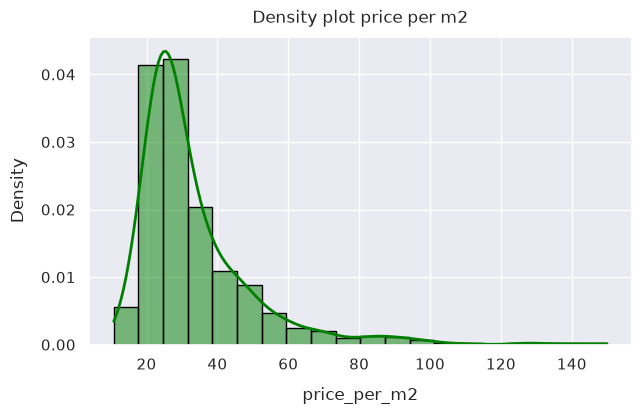

In [64]:
plt.figure(figsize=(7,4))
sns.histplot(df['price_per_m2'], 
             stat='density',
             kde=True, 
             bins=20, 
             color = 'green',
             edgecolor='black',
             line_kws={'linewidth': 2},
            )
plt.title('Density plot price per m2', fontsize=12, pad=10)
plt.xlabel('price_per_m2', fontsize=12, labelpad=10)
plt.ylabel('Density', fontsize=12, labelpad=10)
plt.grid(True)
plt.show()

### Quantile-Quantile (QQ-) plot

      area       var
682    8.0 -2.034006
185   10.0 -1.983540
107   11.0 -1.958307
190   14.0 -1.882608
154   15.0 -1.857376
..     ...       ...
401  232.0  3.618182
291  240.0  3.820046
205  250.0  4.072376
686  270.0  4.577035
445  282.0  4.879831

[775 rows x 2 columns]


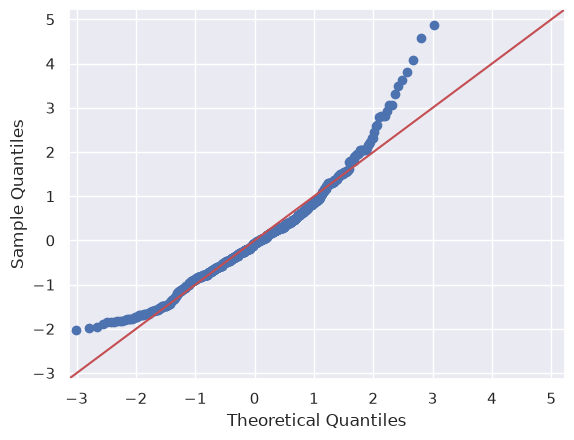

In [65]:
# Variable (standardized)
x = 'area'
df_qq = df.copy()
df_qq['var'] = (df[x]-df[x].mean()) / df[x].std()
print(df_qq.sort_values('var')[['area', 'var']])
    
# Plot
sm.qqplot(df_qq['var'], line ='45')
py.show()

### Barchart  (matplotlib)

In [66]:
# Group data by rooms (only the topmost 15 values are shown)
df_bar = df['rooms'].value_counts().nlargest(15).sort_values(ascending=True)

# Values for barchart
napart = list(df_bar.values)
index = list(df_bar.index.values)
index

[np.float64(8.5),
 np.float64(7.0),
 np.float64(6.0),
 np.float64(5.0),
 np.float64(7.5),
 np.float64(6.5),
 np.float64(4.0),
 np.float64(1.5),
 np.float64(2.0),
 np.float64(3.0),
 np.float64(5.5),
 np.float64(1.0),
 np.float64(2.5),
 np.float64(4.5),
 np.float64(3.5)]

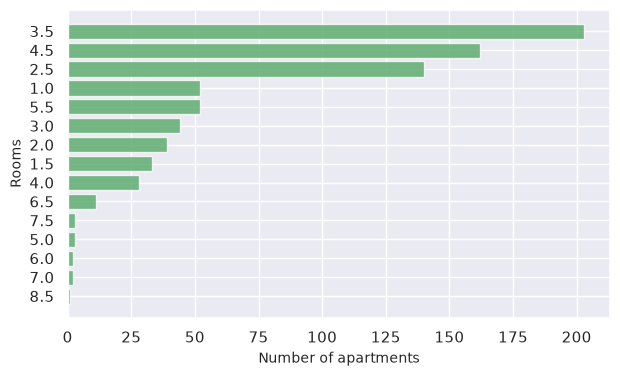

In [67]:
# Group data by rooms (only the topmost 15 values are shown)
df_bar = df['rooms'].value_counts().nlargest(15).sort_values(ascending=True)

# Values for barchart
napart = list(df_bar.values)
index = list(df_bar.index.values)
y_pos = np.arange(len(index))

# Figure
fig, ax = plt.subplots(figsize=(7,4))
ax.barh(y_pos, napart, align='center', color='g', alpha=0.8)
ax.set_yticks(y_pos, index)
ax.set_xlabel('Number of apartments', fontsize=10)
ax.set_ylabel('Rooms', fontsize=10)

# Show graph
plt.show()

### Piechart (matplotlib)

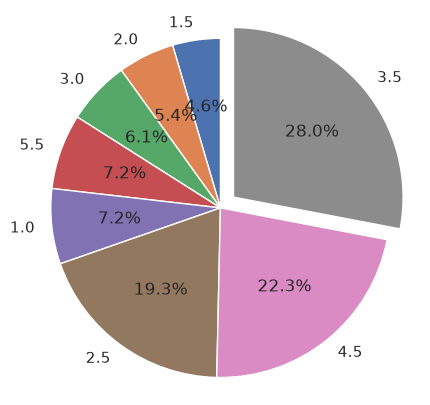

In [68]:
# Group data by rooms (only the 8 most frequently occurencies by rooms)
df_bar = df.rooms.value_counts().nlargest(8).sort_values(ascending=True)

# Simple bar chart
sizes = list(df_bar.values)
labels = list(df_bar.index.values)
explode = [0.1 if i == len(sizes) - 1 else 0 for i in range(len(sizes))]  # moves the largest piece out

fig1, ax1 = plt.subplots(figsize=(5,5))
ax1.pie(sizes, 
        labels=labels, 
        explode=explode,
        autopct='%1.1f%%',
        shadow=False, 
        startangle=90)
ax1.axis('equal')  # ensures that pie is drawn as a circle.

plt.show()

## Multivariate graphical exploratory data analysis (EDA)

### Scatterplot (matplotlib)

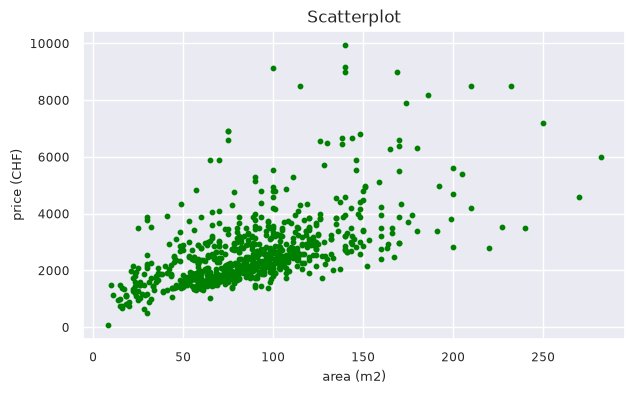

In [76]:
plt.figure(figsize=(7,4))
plt.scatter(df['area'], 
           df['price'], 
           color="green", 
           alpha=1.0,
           s=10)
plt.title('Scatterplot', fontsize=12)
plt.xlabel('area (m2)')
plt.ylabel('price (CHF)')
plt.show()

### Scatterplot (matplotlib) with regression line

(761, 16)
18.974294966029934
985.8582749125486


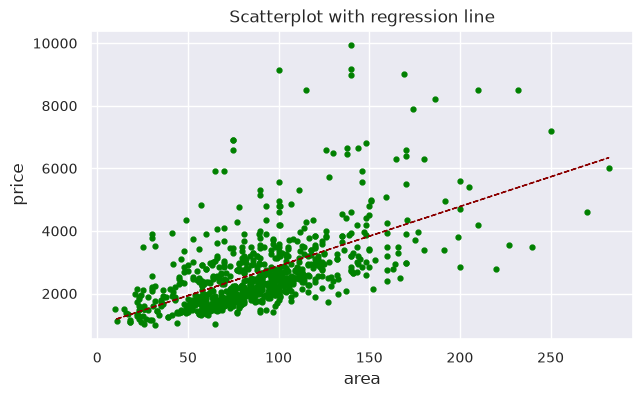

In [77]:
# Subset
df_sub = df.loc[(df.price >= 1000)]
print(df_sub.shape)

# Scatterplot
plt.figure(figsize=(7,4))
plt.plot(df_sub.area, 
         df_sub.price, 
         'o', 
         markersize=3.5,
         color="green")

# Regression line (b = slope, a=intercept)
b, a = np.polyfit(df_sub.area, df_sub.price, 1)
print(b)
print(a)

# Plot regression line
plt.plot(df_sub.area, 
         b*df_sub.area + a, 
         linewidth=1,
         linestyle='dashed',
         color='darkred')

# Add title and axes labels
plt.title('Scatterplot with regression line', fontsize=12)
plt.ylabel('price', fontsize=12)
plt.xlabel('area', fontsize=12)

# Set fontsize of tick labels
plt.xticks(fontsize = 10)
plt.yticks(fontsize = 10)

plt.show()

### Scatterplot-matrix (seaborn)

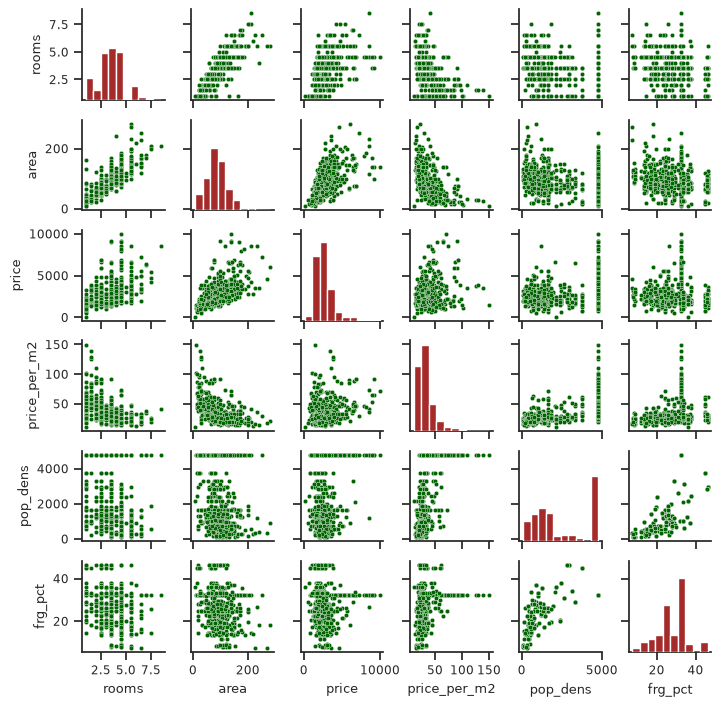

In [78]:
sns.set(style="ticks", font_scale=0.8)
g = sns.PairGrid(df[['rooms', 
                     'area', 
                     'price', 
                     'price_per_m2',
                     'pop_dens',
                     'frg_pct']], 
                 height=1.2, 
                 aspect=1)
g.map_upper(sns.scatterplot,color='darkgreen', s=10)
g.map_lower(sns.scatterplot, color='darkgreen', s=10)
g.map_diag(plt.hist, color='brown')

### Hexagonal binning plot  (matplotlib)

(744, 16)


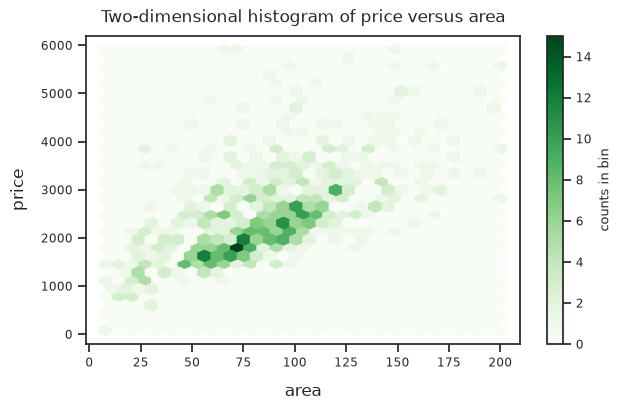

In [79]:
# Subset
df_sub = df.loc[(df.price <= 6000) & (df.area <= 200)]
print(df_sub.shape)

# Plot
fig = plt.figure( figsize=(7,4) )
plt.hexbin(df_sub.area, df_sub.price, gridsize=30, cmap='Greens')

# Set labels
plt.xlabel('area', fontsize=12, labelpad=10)
plt.ylabel('price', fontsize=12, labelpad=10)
plt.title('Two-dimensional histogram of price versus area', fontsize=12, pad=10)

cb = plt.colorbar(label='count in bin')
cb.set_label('counts in bin')

### Correlation heatmap (seaborn)

<Axes: >

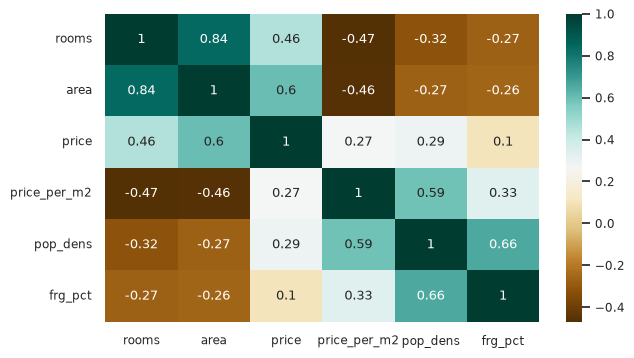

In [80]:
# Set font size for plot
sns.set(font_scale=0.8)

# Create correlation matrix as the basis for the heatmap
plt.figure(figsize=(7,4))
corr = df[['rooms', 
                     'area', 
                     'price', 
                     'price_per_m2',
                     'pop_dens',
                     'frg_pct']].corr().round(2)

# Plot heatmap
sns.heatmap(corr, 
            cmap="BrBG", 
            annot=True)

### Bubble plot (seaborn)

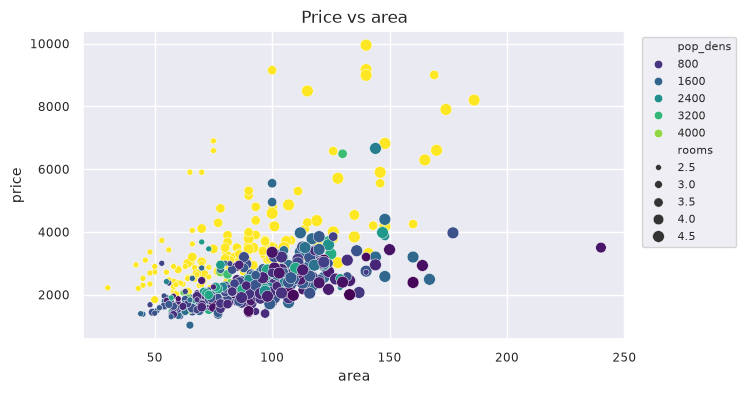

In [81]:
# Subset of df
df_sub = df.loc[(df['rooms'] >= 2.5) & (df['rooms'] <= 4.5)]

plt.figure(figsize=(7,4))
plt.ticklabel_format(style='plain')

ax = sns.scatterplot(x="area", 
                     y="price",
                     size="rooms", # determines bubble size
                     hue="pop_dens",  # determines color
                     palette="viridis",  # continuous palette for a numeric variable
                     data=df_sub)

# Set title and axes
ax.set_title('Price vs area', fontsize = 12)
ax.set_xlabel('area', fontsize = 10)
ax.set_ylabel('price', fontsize = 10)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)  # legend outside the plot

### b identify the outliner 

Bearbeite Aufgabe b) im Notebook zur explorativen Datenanalyse der Zürcher Wohnungsdaten.

Untersuche die vorhandenen Statistiken und Grafiken auf mögliche Ausreißer. Achte insbesondere auf Wohnungen mit ungewöhnlich großer Wohnfläche sowie auf auffällig niedrige oder hohe Mietpreise pro m².

Es gibt keine allgemeingültige Definition eines Ausreißers. Beschreibe deshalb nachvollziehbar, welche Werte du als auffällig einstufst und worauf deine Einschätzung beruht (z. B. Verteilung, Boxplot oder statistische Kennzahlen). Zeige die betreffenden Datensätze beziehungsweise eine übersichtliche Zusammenfassung und erläutere kurz, warum sie auffallen.

Verändere oder entferne keine Daten. Ergänze die Analyse und ihre Interpretation im Notebook und führe geänderte Codezellen aus, um sie zu überprüfen.
``````text
Analysiere Aufgabe b) im geöffneten Notebook mit den Zürcher Wohnungsdaten. Untersuche die vorhandenen Statistiken und Grafiken auf mögliche Ausreißer. Achte besonders auf Wohnungen mit extrem großer Wohnfläche sowie auf ungewöhnlich niedrige oder hohe Mietpreise pro m².

Da es keine eindeutige Definition eines Ausreißers gibt, erläutere deine Kriterien und begründe anhand der Daten und Grafiken, warum bestimmte Werte auffällig sind. Zeige die auffälligen Datensätze oder fasse sie übersichtlich zusammen. Entferne oder verändere keine Daten. Ergänze die Analyse und eine kurze Interpretation im Notebook und führe neue Codezellen aus.

### result of task 2

After filtering, 775 apartments remain. The mean living area decreases from 92.7 to 88.6 m², and the maximum falls from 1,633 to 282 m², while the median remains unchanged at 86 m². The minimum rent per m² rises from CHF 0.04 to CHF 10.75. This suggests that a few extreme listings affected the statistics, although unusual values are not necessarily errors.

### compare the results of the two notebooks

The rural subset contains **81 apartments from 36 municipalities**, while the city subset contains **257 apartments, all from Zürich**. Rural apartments are larger (median **109 m²** vs. **70 m²**) but cheaper per square metre (median **CHF 22.43/m²** vs. **CHF 41.79/m²**). City apartments have a higher median rent (**CHF 2,900** vs. **CHF 2,420**) despite being smaller.

Overall, the results suggest that apartments in Zürich are smaller and considerably more expensive per square metre than apartments in the rural municipalities.

### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [82]:
import os
import platform
import socket
from platform import python_version
from datetime import datetime

print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime("%Y-%m-%d %H:%M:%S"))
print('Python Version:', python_version())
print('-----------------------------------')

-----------------------------------
POSIX
Linux | 6.8.0-1070-azure
Datetime: 2026-11-20 08:15:51
Python Version: 3.11.18
-----------------------------------
